In [14]:
# Imports
import ROOT
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [15]:
# Global variables
dataPath = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/"
filename = dataPath + "DmlNtup_Data_8years_FullPhotonData_AllSky.root"

In [16]:
tree = None
f = ROOT.TFile(filename, "READ") 

tree = f.Get("DmlNtup")
print(tree)
print(type(tree))

Name: DmlNtup Title: DmlNtup
<class cppyy.gbl.TTree at 0x387e040>


In [17]:
# Print general informations about the tree
print(f"Name : {tree.GetName()}")
print(f"Number of entries : {tree.GetEntries()}") # Number of entries
print(f"Number of branches : {tree.GetListOfBranches().GetEntries()}. Name of branches : ") # Number of branches

# List all branches of the tree
#for branch in tree.GetListOfBranches():
 #   print(branch.GetName())


Name : DmlNtup
Number of entries : 320681
Number of branches : 424. Name of branches : 


In [18]:
# Latitude spans from -90° to 90° ; longitude spans from -180° to 180°
df = ROOT.RDataFrame(tree)
maxLat = df.Max("celestialcoordBest_3").GetValue()/(2*np.pi)*360
minLat = df.Min("celestialcoordBest_3").GetValue()/(2*np.pi)*360

maxLong = df.Max("celestialcoordBest_2").GetValue()/(2*np.pi)*360
minLong = df.Min("celestialcoordBest_2").GetValue()/(2*np.pi)*360

print(f"Latitude spans from {minLat} to {maxLat}")
print(f"Longitude spans from {minLong} to {maxLong}")

# Conclusion : need to convert longitude to -180 - 180

Latitude spans from -89.67278863191036 to 89.65410806453039
Longitude spans from 0.00018620734699823874 to 359.99973681034584


In [19]:
%%cpp 

double rad2deg(double x) {
    return x / (2*M_PI) * 360;
}

In [20]:
# Create new converted columns
dfConverted = df.Define("longitudeConverted", "rad2deg(celestialcoordBest_2)").Define("latitudeConverted", "rad2deg(celestialcoordBest_3)")

In [21]:
# Test conversion

maxLat = dfConverted.Max("latitudeConverted").GetValue()
minLat = dfConverted.Min("latitudeConverted").GetValue()

maxLong = dfConverted.Max("longitudeConverted").GetValue()
minLong = dfConverted.Min("longitudeConverted").GetValue()

print(f"Latitude spans from {minLat} to {maxLat}")
print(f"Longitude spans from {minLong} to {maxLong}")

# Conclusion : conversion success

Latitude spans from -89.67278863191036 to 89.65410806453039
Longitude spans from 0.00018620734699823874 to 359.99973681034584


In [22]:
# Create histogram 2D
h = dfConverted.Histo2D(("galMap", "Galactic Distribution of Photon Counts;l [deg];b [deg]", 400, 0, 360, 400, -90, 90),
                        "longitudeConverted", "latitudeConverted")


In [23]:
# Plot the map
c = ROOT.TCanvas()
h.Draw("MOLLWEIDE COLZ")
c.Draw()

# Conclusion : ROOT does not allow for our projection

In [24]:
npDf = dfConverted.AsNumpy(["longitudeConverted", "latitudeConverted"])
lons = npDf["longitudeConverted"]
lons = -(lons - 360*(lons//180))
lats = npDf["latitudeConverted"]

lons_rad = np.pi*lons/180

lats_rad = np.radians(lats)

# Yields dict with longitude, latitude
print(lons_rad)
print(lats_rad)
print(lons_rad.shape)

[ 3.10098654 -1.52999759 -1.88849592 ...  0.78033239 -1.51666272
 -1.30720317]
[ 0.38752395 -0.13450214  0.03159686 ... -0.76451856  0.01101483
  0.00290434]
(320681,)


In [25]:
figPath = "/home/users/l/lebrun/figures/"

res_n = 4

# Define the edges of the bins for longitude and latitude
lon_bins = np.linspace(-np.pi, np.pi, int(360*res_n))  # Adjust the number of bins as needed
lat_bins = np.linspace(-np.pi/2, np.pi/2, int(180*res_n))

# Calculate the 2D histogram
hist, xedges, yedges = np.histogram2d(lons_rad, lats_rad, bins=[lon_bins, lat_bins])
print(hist.shape)

(1439, 719)


### Plot map

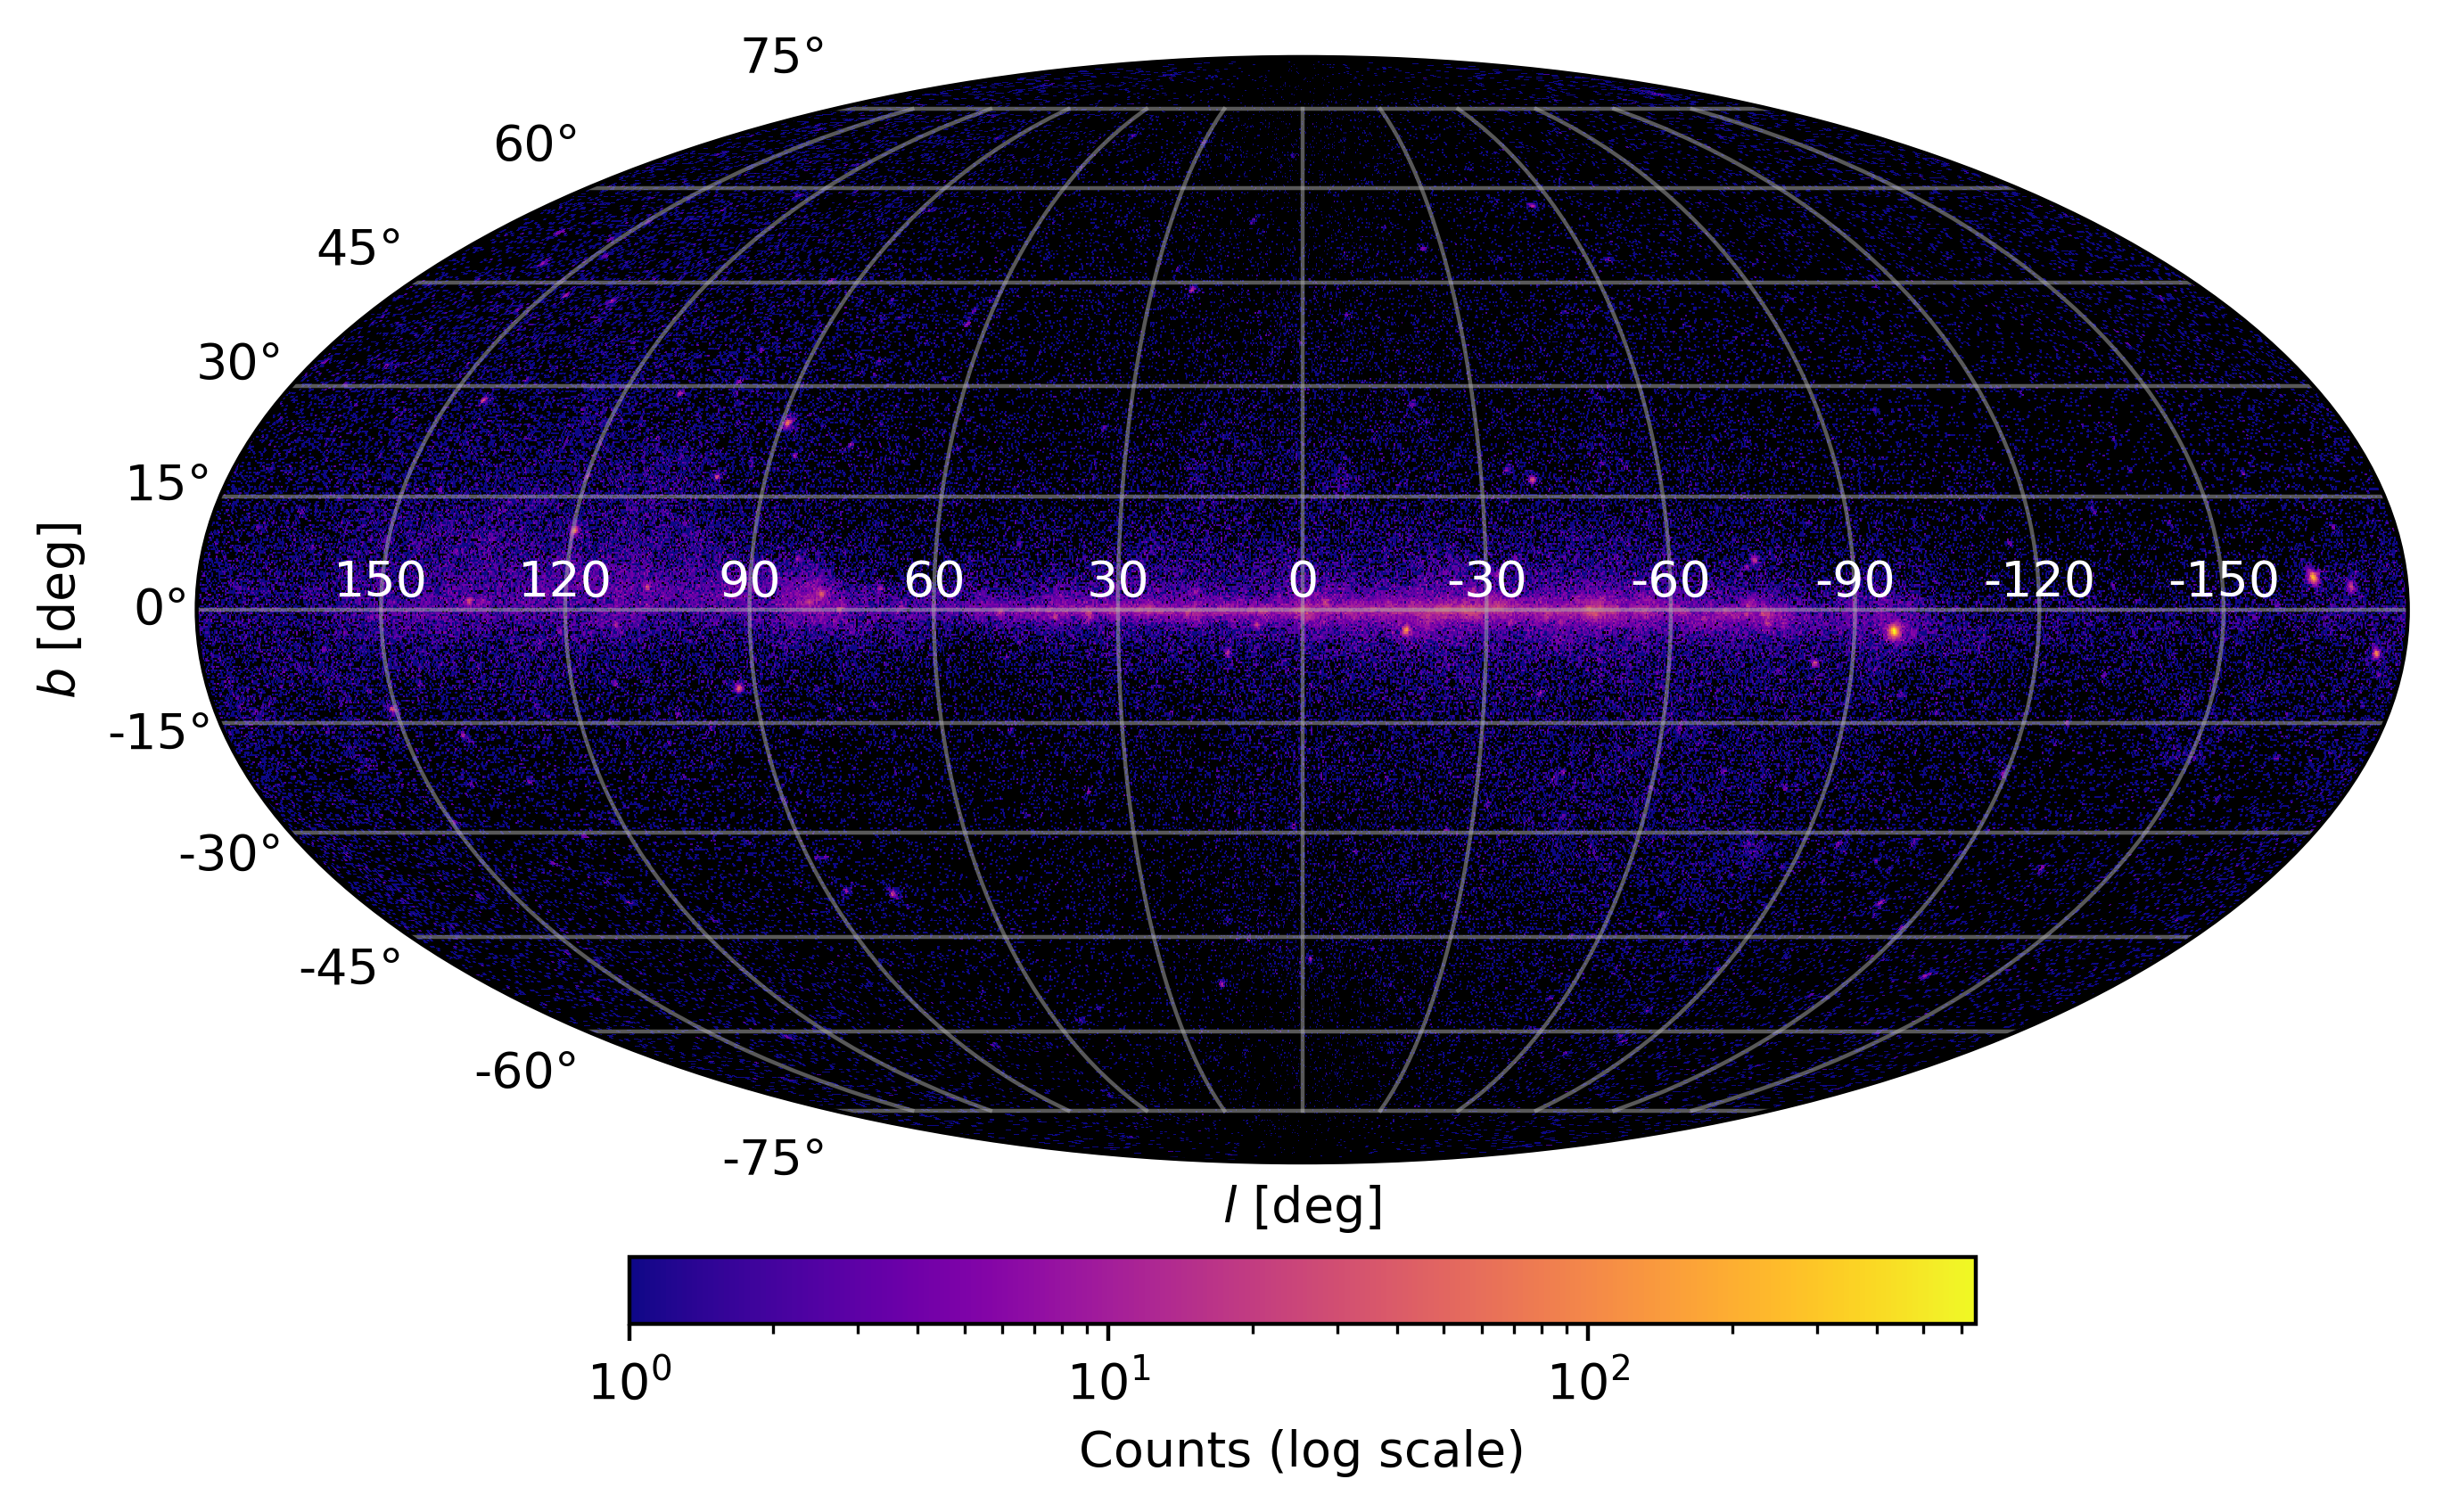

In [26]:
# Création du plot en projection Mollweide
fig2 = plt.figure(figsize=(8, 5))
ax2 = fig2.add_subplot(111, projection="mollweide")
ax2.set_facecolor('black')
# Plot the 2D histogram using pcolormesh
# We use the logarithmic normalization for the color scale
cmap = "plasma"
norm = mcolors.LogNorm()  # Use logarithmic normalization for color scale
pc = ax2.pcolormesh(xedges, yedges, hist.T, cmap=cmap, norm=norm, shading='auto')

# Colorbar
cbar = fig2.colorbar(pc, ax=ax2, orientation="horizontal", fraction=0.05, pad=0.07)
cbar.set_label("Counts (log scale)")

# Modifying axis labels and grid
ax2.xaxis.set_tick_params(labelcolor="white")
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax2.set_xticklabels(tick_labels)
ax2.set_xlabel(r"$l$ [deg]")
ax2.set_ylabel(r"$b$ [deg]")
ax2.grid(True, linestyle="-", alpha=0.5)
fig2.savefig(figPath+"map.pdf")
# Show the plot
plt.show()

## Compute flux 

### Load exposure map

In [27]:
dirDir = "/home/users/l/lebrun/"
resultPath = dirDir + "results/"

filename = "normalized_exposure_map.npy"
exposure = np.load(resultPath + filename)
print(exposure.shape)

(1439, 719)


### Initialize lifetime

In [28]:
lifetime = 1.9182978e8 
print(exposure)
print(np.min(exposure), np.max(exposure))

[[1.97728994 0.         1.5951887  ... 0.         1.16694375 0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         1.25913802 ... 2.2923535  0.         0.        ]
 ...
 [0.         0.         0.66536893 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 1.67319365 1.0262016  0.        ]
 [0.         0.         1.06162205 ... 0.         0.         0.        ]]
0.0 161.1742564100936


### Load Acceptance

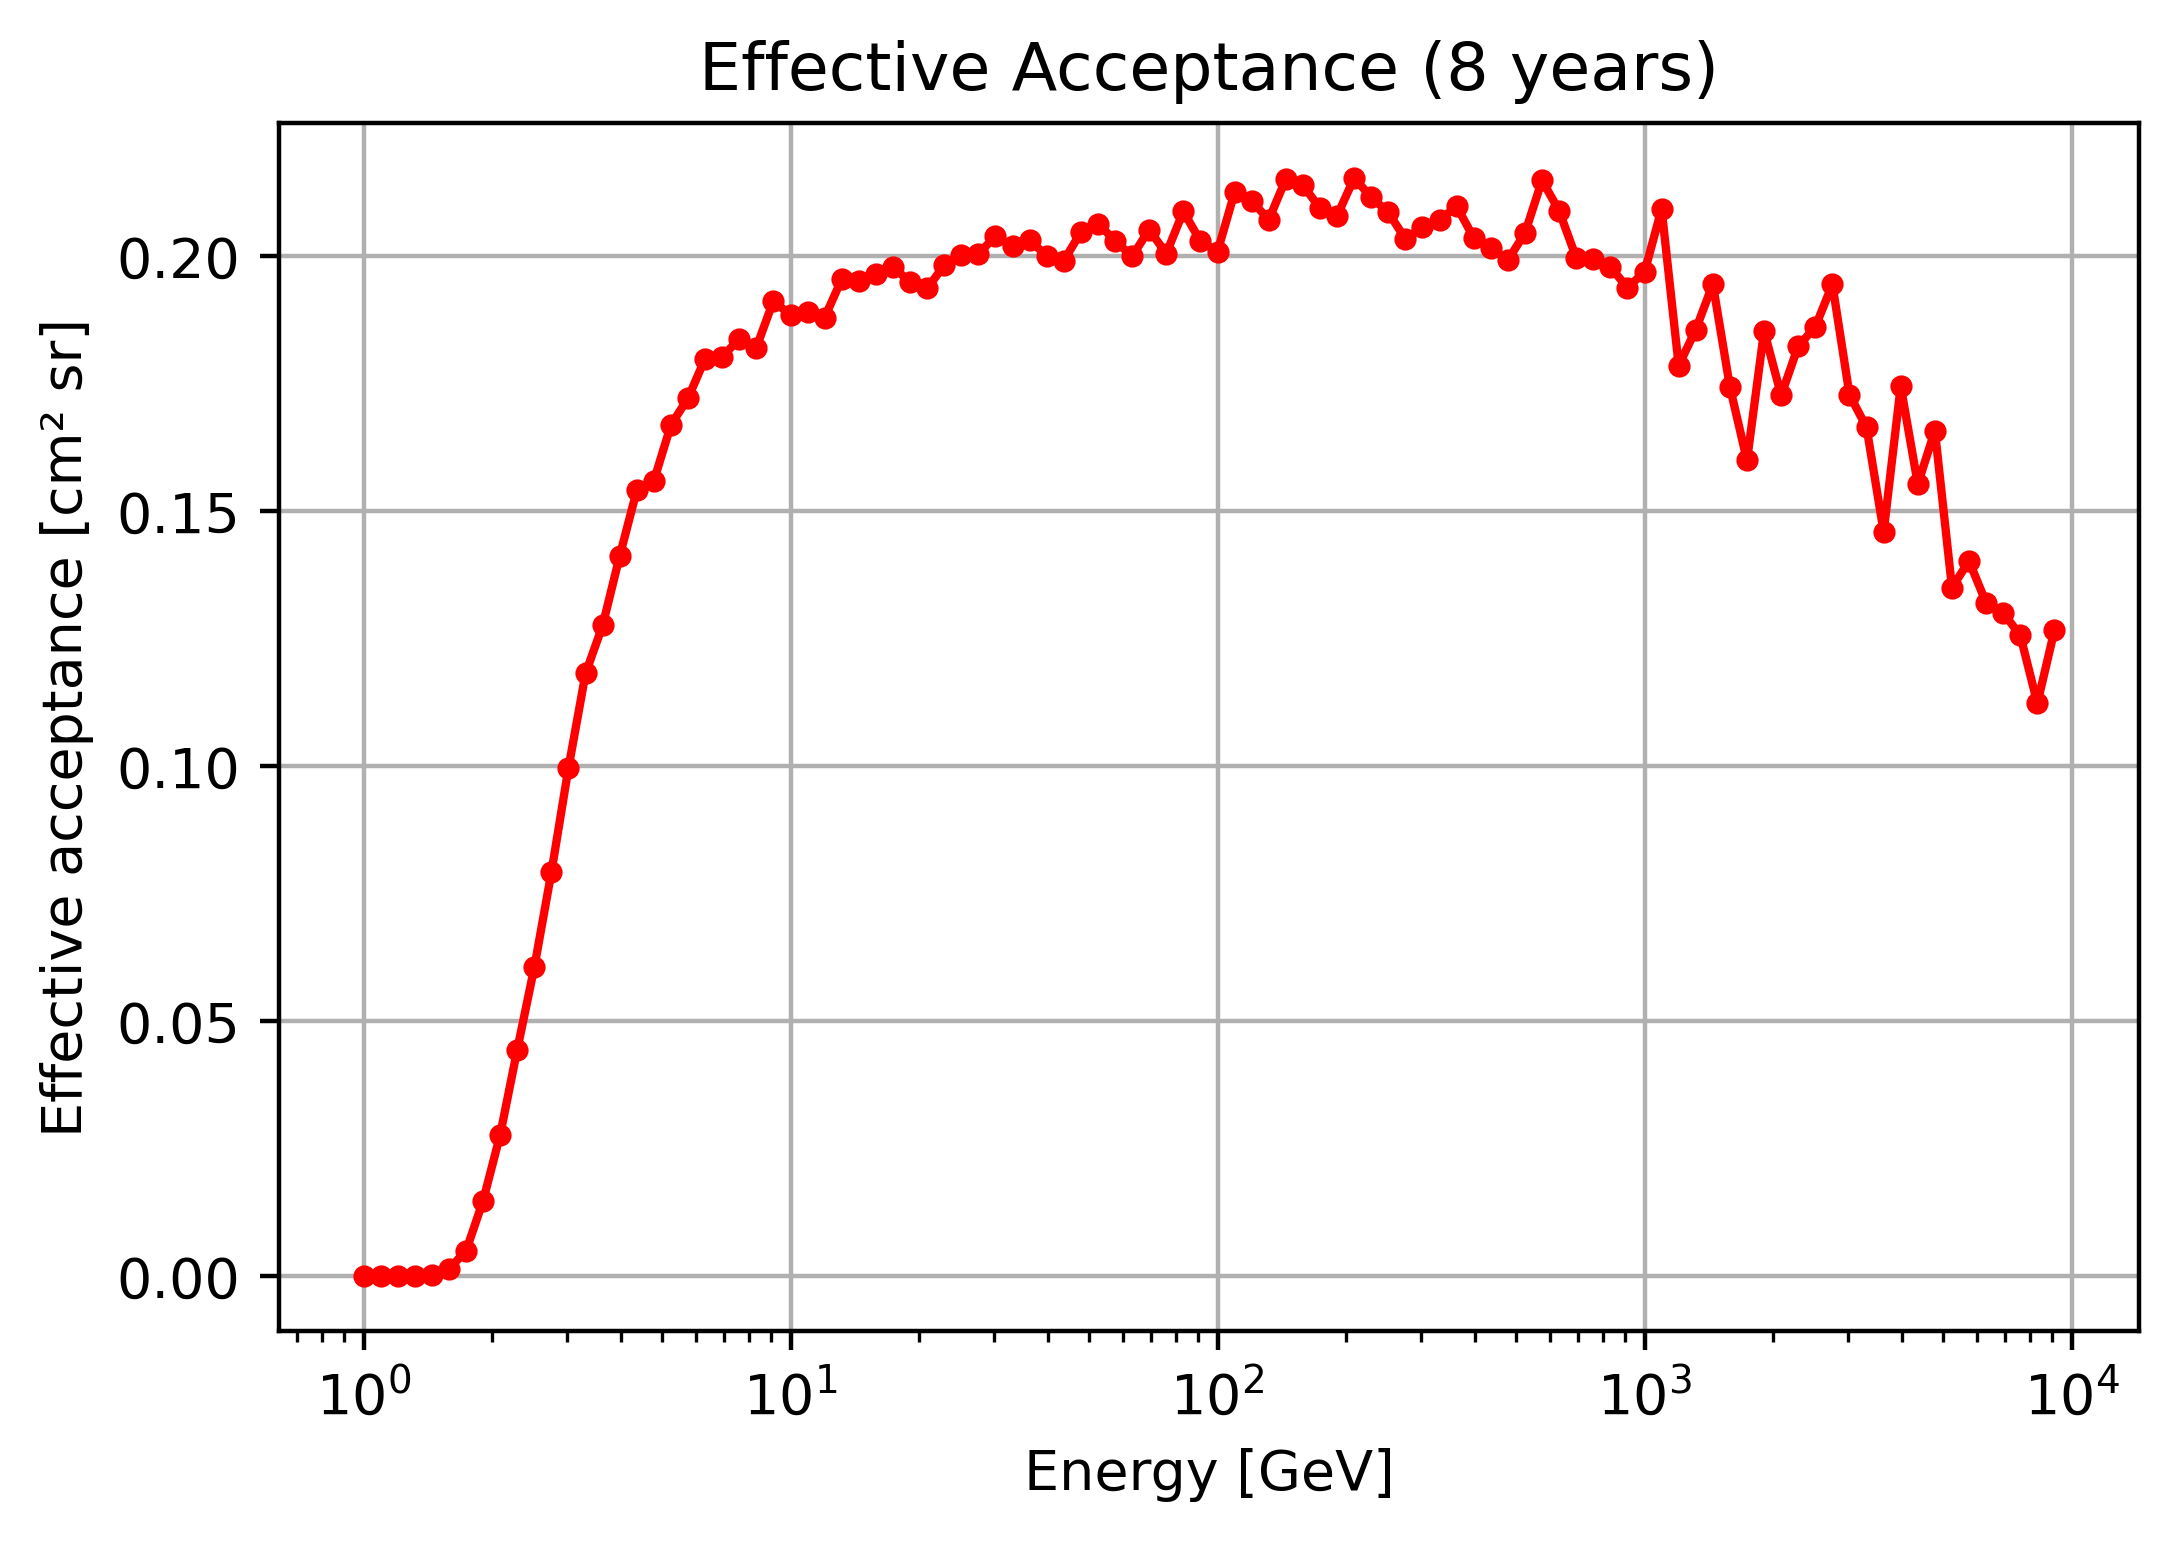

In [29]:
# Load acceptance       
localDataPath = "/home/users/l/lebrun/data/"
acceptance = np.loadtxt(localDataPath+"acceptance_vs_energy_cutBDT_v25.txt") # 100 values

ene = np.logspace(1, 5, 101) / 10 
fig, ax = plt.subplots()
ax.semilogx(ene[:-1], acceptance, "r.-")
ax.set_xlabel("Energy [GeV]")
ax.set_ylabel("Effective acceptance [cm² sr]")
ax.set_title("Effective Acceptance (8 years)")
ax.grid()
fig.savefig(figPath+"acceptance.pdf")

In [31]:
from scipy import interpolate

def create_acceptance_function(energy_edges, acceptance_values):
    """
    Creates an interpolation function that returns acceptance values
    for given energy inputs.
    
    Parameters:
    energy_values (array): Array of energy values in log scale
    acceptance_values (array): Array of corresponding acceptance values
    
    Returns:
    function: Interpolation function that takes energy as input and returns acceptance
    """
    # Calculate bin centers (geometric mean for log-spaced bins)
    energy_centers = np.sqrt(energy_edges[:-1] * energy_edges[1:])
    # Create interpolation function
    # We use 'linear' interpolation which works well for log-scaled data
    interp_func = interpolate.interp1d(
        energy_centers,
        acceptance_values,
        kind='linear',
        bounds_error=False,  # Don't raise error for out-of-bounds values
        fill_value=(acceptance_values[0], acceptance_values[-1])  # Extrapolate using edge values
    )
    
    return interp_func

# Create the function
acceptance_function = create_acceptance_function(ene, acceptance)  # Note: ene has 101 values but acceptance has 100

# TEST
energy_centers = np.sqrt(ene[:-1] * ene[1:])
test_energy = np.mean((energy_centers[40], energy_centers[41]))
expected_A = np.mean((acceptance[40], acceptance[41]))
interpolated_acceptance = acceptance_function(test_energy)
print(f"Energy index 40 : {energy_centers[40]}, acceptance {acceptance[40]}")
print(f"Energy index 41 : {energy_centers[41]}, acceptance {acceptance[41]}")
print(f"Acceptance at energy {test_energy} = {interpolated_acceptance} ; expected {expected_A}")

Energy index 40 : 41.68693834703355, acceptance 0.200052645377
Energy index 41 : 45.708818961487495, acceptance 0.199120136823
Acceptance at energy 43.69787865426052 = 0.1995863911 ; expected 0.19958639109999998


### Divide map by (acceptance * exposure * lifetime)

In [ ]:
hist_tmp = hist / (acceptance_function(hist) * lifetime * exposure) # /!\ Error : acceptance takes energies as input
hist_flux = np.copy(hist)
hist_flux[hist_flux != 0] = hist_tmp[hist_flux != 0]

/tmp/ipykernel_2446313/304066359.py:1: RuntimeWarning: divide by zero encountered in divide
  hist_tmp = hist / (acceptance_function(hist) * lifetime * exposure)
/tmp/ipykernel_2446313/304066359.py:1: RuntimeWarning: invalid value encountered in divide
  hist_tmp = hist / (acceptance_function(hist) * lifetime * exposure)


### Plot Flux map

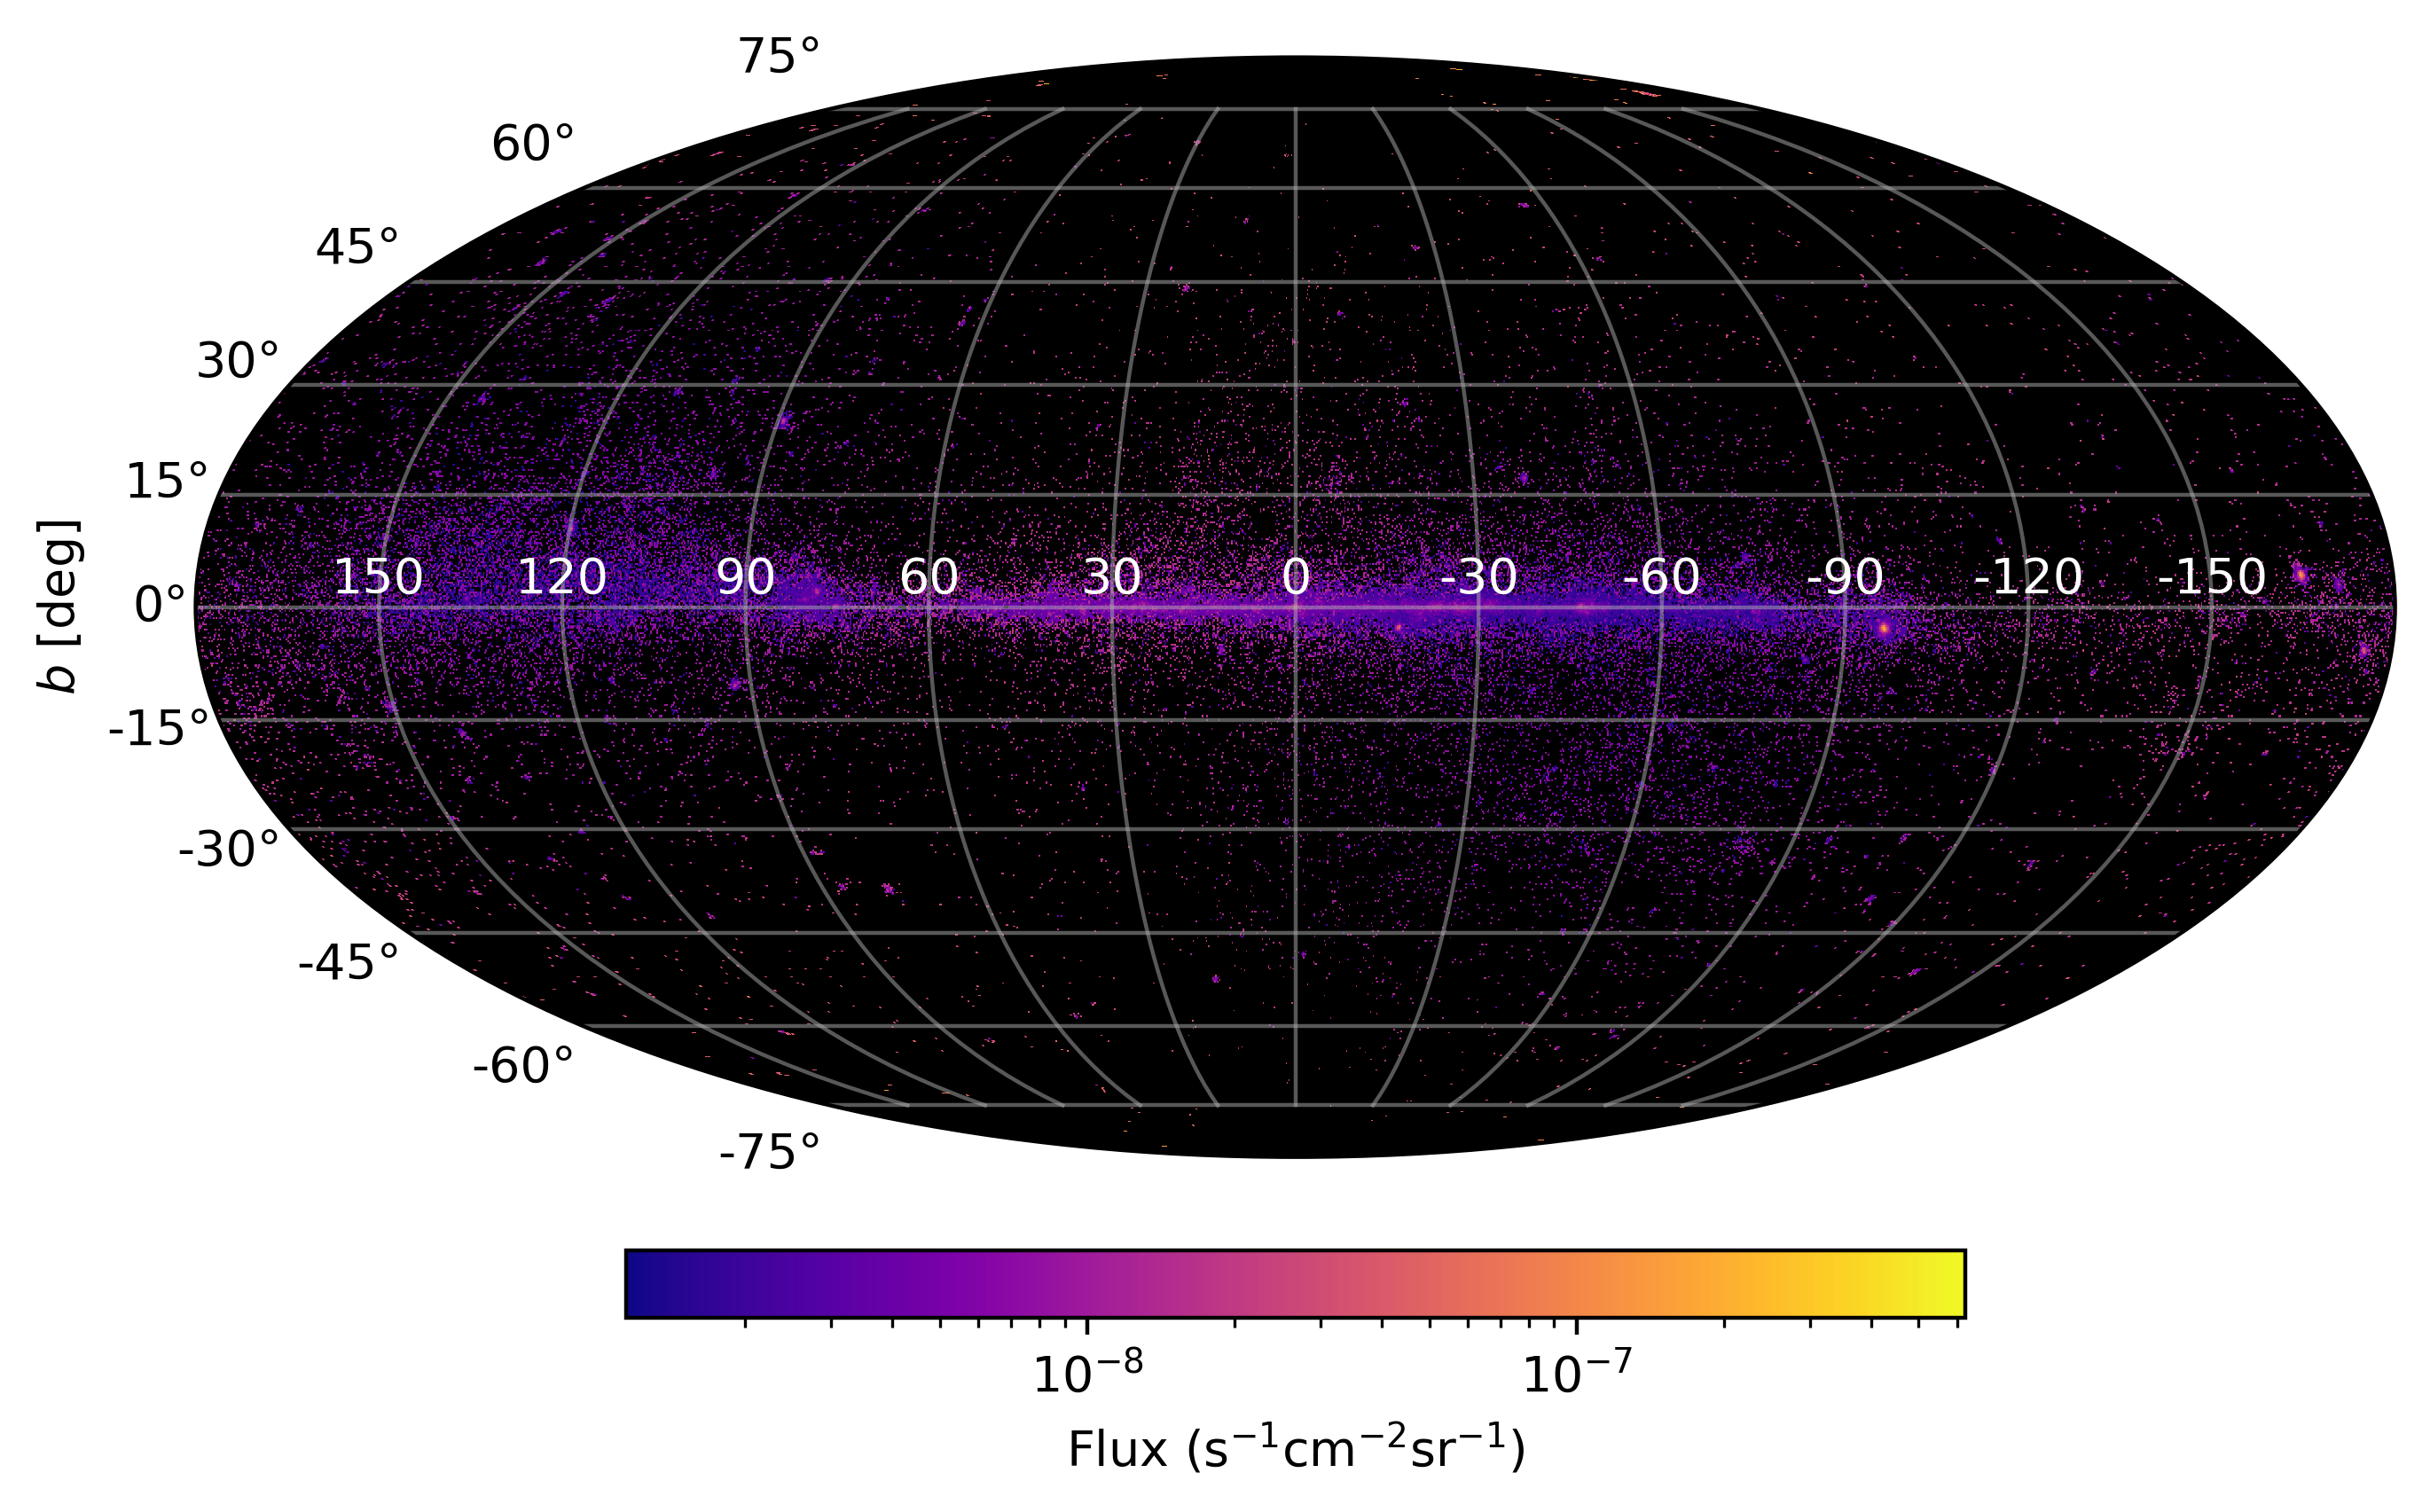

In [33]:
# Création du plot en projection Mollweide
fig3 = plt.figure(figsize=(8, 5))
ax3 = fig3.add_subplot(111, projection="mollweide")
ax3.set_facecolor('black')
# Plot the 2D histogram using pcolormesh
# We use the logarithmic normalization for the color scale
cmap = "plasma"
norm = mcolors.LogNorm()  # Use logarithmic normalization for color scale
pc = ax3.pcolormesh(xedges, yedges, hist_flux.T, cmap=cmap, norm=norm, shading='auto')

# Colorbar
cbar = fig3.colorbar(pc, ax=ax3, orientation="horizontal", fraction=0.05, pad=0.07)
cbar.set_label(r"Flux (s$^{-1}$cm$^{-2}$sr$^{-1}$)")

# Modifying axis labels and grid
ax3.xaxis.set_tick_params(labelcolor="white")
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax3.set_xticklabels(tick_labels)
ax3.set_ylabel(r"$b$ [deg]")
ax3.grid(True, linestyle="-", alpha=0.5)
fig3.savefig(figPath+"FluxMap.pdf")
# Show the plot
plt.show()